### Assignment:  -12-

**Deep Neural Networks in Keras: Dry Bean Classification**

### 2. Context & Scenario
You are supporting an agricultural quality-control team that wants to classify dry bean varieties from image-derived measurements. The organization needs a Keras-based neural network workflow that is reproducible, auditable, and suitable for later deployment in a monitored production environment. Your objective is not only to obtain strong predictive performance, but also to demonstrate disciplined data handling, leakage prevention, and defensible evaluation. Treat this as an ML systems task in which modeling choices must be justified technically and operationally.

### 3. Dataset
**Dataset name:** UCI Dry Bean Dataset

**Access links:**  
- Dataset page: https://archive.ics.uci.edu/dataset/602/dry+bean+dataset  
- Direct download: https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip  

The dataset contains approximately 13,611 observations, where each row represents one bean measured from an image. It includes 16 numeric geometric and shape features and a 7-class target label identifying bean variety. The unit of analysis is an individual bean; the task is multiclass classification on tabular data. This dataset is appropriate for examining feature scaling, skew, class balance, and model diagnostics for dense neural-network baselines.

**Licensing/usage note:** UCI lists this dataset under CC BY 4.0;

### 4. Machine Learning Tasks
- Load the dataset and verify the target, feature schema, and record counts before modeling.  
- Implement validation guardrails, including checks for missing values, dtypes, valid label categories, and plausible numeric ranges, to catch upstream data issues early.  
- Perform concise EDA using summary statistics, class distribution, feature skew, and at least one feature-relationship view to motivate preprocessing and modeling choices.  
- Design preprocessing with leakage-safe train/validation/test splits, feature scaling via `StandardScaler`.  
- Select and justify a Keras dense-network baseline for multiclass classification, including output configuration, stopping strategy, and any regularization choices.  
- Evaluate results with learning curves, confusion matrix, accuracy, and macro/weighted F1, then interpret which errors matter most for the application.  
- Discuss systems considerations, including reproducibility controls, experiment logging, monitoring signals, drift detection, compute cost, and rollback criteria for deployment.

### 5. Deliverables
- One executed Jupyter notebook with code, outputs, plots, and concise Markdown interpretations.  
- A brief evaluation summary covering preprocessing decisions, selected model, and class-wise diagnostic findings.  
- A short reflection on reproducibility, monitoring, drift, deployment risk, and next experiments.

### 6. Grading Rubric (100 points)

| Category | Points | Criteria |
|---|---:|---|
| Code correctness | 20 | Notebook runs cleanly; code is logically correct; outputs, plots, and metrics are produced without execution errors. |
| Data quality / validation | 15 | Validation checks are appropriate, clearly reported, and capable of catching realistic schema or data-quality failures. |
| EDA | 15 | EDA is concise, relevant, and used to justify preprocessing and modeling decisions. |
| Modeling / evaluation | 20 | Model choice is appropriate; preprocessing is leakage-safe; evaluation uses suitable metrics and diagnostics for multiclass classification. |
| Interpretation | 15 | Written analysis correctly explains model behavior, trade-offs, and limitations using observed results. |
| ML-systems thinking | 15 | Work addresses reproducibility, monitoring, drift, compute cost, and rollback or recovery planning in a technically credible way. |
| **Total** | **100** |  |


_______________________________________________________________________________________________________________________________________________

# Deep Neural Networks in Keras: Dry Bean Classification

This assignment is used to create a neural network to classify different types of dry beans using measurements taken from images. The UCI Dry Bean dataset contains 16 numerical features relating to the size and shape of individual beans. There are 7 different types of beans which are given as the target variable. Using TensorFlow and Keras I will attempt to create a reproducible classification pipeline. This will include data quality checks, exploratory data analysis, avoiding data leakage when preprocessing, creating a dense neural network and assessing the models performance. The model will also be considered in terms of how it could be monitored and maintained in a production environment.

In [37]:
import os
import random
import zipfile
import urllib.request
import time
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import joblib

RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Random state:", RANDOM_STATE)

TensorFlow version: 2.21.0
NumPy version: 2.5.3
Pandas version: 2.3.3
Random state: 42


## Dataset Loading

The UCI Dry Bean dataset consists of feature values derived from pictures of a single Dry Bean. Each observation is a single bean that has 16 features and a Class variable which is categorical. This data was downloaded from the UCI Machine Learning Repository and imported from an Excel file.

In [38]:
# download the dataset
url = "https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip"

zip_path = "dry_bean_dataset.zip"
extract_folder = "dry_bean_data"

if not os.path.exists(zip_path):
    urllib.request.urlretrieve(url, zip_path)

# create the extraction folder
if not os.path.exists(extract_folder):
    os.makedirs(extract_folder)

# extract the dataset
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_folder)

# find the file
excel_file = None

for root, dirs, files in os.walk(extract_folder):
    for file in files:
        if file.endswith(".xlsx"):
            excel_file = os.path.join(root, file)
            break

    if excel_file is not None:
        break

if excel_file is None:
    raise FileNotFoundError("The Excel dataset could not be found.")

# load the dataset
df = pd.read_excel(excel_file)

print("Dataset loaded successfully.")
print("Dataset file:", excel_file)
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully.
Dataset file: dry_bean_data\DryBeanDataset\Dry_Bean_Dataset.xlsx
Dataset shape: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## Initial Dataset Inspection

The dataset is inspected to verify the number of observations, feature columns, target variable, and data types. This helps confirm that the downloaded data matches the expected structure before preprocessing begins.

In [39]:
# first five rows
display(df.head())

# dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# column names
print("\nColumn names:")
print(df.columns.tolist())

# data types
print("\nData types:")
print(df.dtypes)

# dataset information
print("\nDataset information:")
df.info()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


Number of rows: 13611
Number of columns: 17

Column names:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']

Data types:
Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class               object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           ----------

In [40]:
# identify the target column
target_column = "Class"

if target_column not in df.columns:
    raise ValueError("The target column 'Class' was not found.")

# separate features and target
X = df.drop(columns=[target_column])
y = df[target_column]

print("Number of features:", X.shape[1])
print("Target column:", target_column)
print("Target classes:", sorted(y.unique()))

print("\nFeature columns:")
print(X.columns.tolist())

Number of features: 16
Target column: Class
Target classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']

Feature columns:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']


## Data Validation and Quality Checks

There are some checks that can be carried out prior to modelling. These include checking for any missing values, duplicates, incorrect data types, incorrect class labels and unrealistic numeric values within the data set. We expect to have 16 numeric features and 7 different bean varieties. This helps us to identify any potential issues within our source data.

In [41]:
# check for missing values
missing_values = df.isnull().sum()

print("Missing values by column:")
print(missing_values)

print("\nTotal missing values:", df.isnull().sum().sum())

# check for duplicate rows
duplicate_count = df.duplicated().sum()

print("\nDuplicate rows:", duplicate_count)

Missing values by column:
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

Total missing values: 0

Duplicate rows: 68


In [42]:
# remove exact duplicate records
original_rows = len(df)

df = df.drop_duplicates().reset_index(drop=True)

removed_rows = original_rows - len(df)

print("Original rows:", original_rows)
print("Duplicate rows removed:", removed_rows)
print("Remaining rows:", len(df))
print("Remaining duplicates:", df.duplicated().sum())

# separate features and target again after cleaning
X = df.drop(columns=["Class"])
y = df["Class"]

Original rows: 13611
Duplicate rows removed: 68
Remaining rows: 13543
Remaining duplicates: 0


In [43]:
# check the dataset dimensions
print("Expected feature count: 16")
print("Actual feature count:", X.shape[1])

print("\nExpected class count: 7")
print("Actual class count:", y.nunique())

# check numeric feature data types
print("\nAll features numeric:", X.select_dtypes(include=np.number).shape[1] == 16)

# check target categories
valid_classes = [
    "BARBUNYA",
    "BOMBAY",
    "CALI",
    "DERMASON",
    "HOROZ",
    "SEKER",
    "SIRA"
]

print("\nObserved classes:")
print(sorted(y.unique()))

unexpected_classes = set(y.unique()) - set(valid_classes)

print("\nUnexpected classes:", unexpected_classes)

# check for infinite values
print("\nInfinite values:", np.isinf(X.select_dtypes(include=np.number)).sum().sum())

Expected feature count: 16
Actual feature count: 16

Expected class count: 7
Actual class count: 7

All features numeric: True

Observed classes:
['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']

Unexpected classes: set()

Infinite values: 0


In [44]:
# check minimum and maximum values for each feature
print("Feature minimum values:")
print(X.min())

print("\nFeature maximum values:")
print(X.max())

# check whether any feature contains zero or negative values
non_positive_counts = (X <= 0).sum()

print("\nNon-positive values by feature:")
print(non_positive_counts)

# check selected features that should be proportions or ratios
bounded_features = [
    "Eccentricity",
    "Extent",
    "Solidity",
    "roundness",
    "ShapeFactor1",
    "ShapeFactor2",
    "ShapeFactor3",
    "ShapeFactor4"
]

for column in bounded_features:
    if column in X.columns:
        invalid_count = ((X[column] < 0) | (X[column] > 1)).sum()
        print(column, "values outside [0, 1]:", invalid_count)

Feature minimum values:
Area               20420.000000
Perimeter            524.736000
MajorAxisLength      183.601165
MinorAxisLength      122.512653
AspectRation           1.024868
Eccentricity           0.218951
ConvexArea         20684.000000
EquivDiameter        161.243764
Extent                 0.555315
Solidity               0.919246
roundness              0.489618
Compactness            0.640577
ShapeFactor1           0.002778
ShapeFactor2           0.000564
ShapeFactor3           0.410339
ShapeFactor4           0.947687
dtype: float64

Feature maximum values:
Area               254616.000000
Perimeter            1985.370000
MajorAxisLength       738.860153
MinorAxisLength       460.198497
AspectRation            2.430306
Eccentricity            0.911423
ConvexArea         263261.000000
EquivDiameter         569.374358
Extent                  0.866195
Solidity                0.994677
roundness               0.990685
Compactness             0.987303
ShapeFactor1            0.01

In [69]:
# stop execution if important data-quality checks fail
assert X.shape[1] == 16, "Unexpected number of features."
assert y.nunique() == 7, "Unexpected number of classes."
assert X.isnull().sum().sum() == 0, "Missing feature values detected."
assert np.isfinite(X.to_numpy()).all(), "Infinite values detected."
assert set(y.unique()) == set(valid_classes), "Unexpected class labels."

print("All validation guardrails passed.")

All validation guardrails passed.


These diagnostic tests will allow us to see how the data are structured and what numbers we have. We would expect our features to be numerical and our target variable to contain 7 valid bean varieties. If there are any missing data, duplicate data, infinite values or out of range values these will be highlighted so we can investigate any potential data quality issues. These tests are not automatic removal but help us understand where there may be an issue.

## Exploratory Data Analysis

Exploratory data analysis was performed to understand the distribution of classes within our target variable and numerical features. Summary statistics, counts, skewness and correlation were considered to give us an idea about how to preprocess our data.

In [45]:
# display summary statistics for the numerical features
display(X.describe().T)

,count,mean,std,min,25%,50%,75%,max
Area,13543.0,53048.460385,29392.438324,20420.000000,36282.500000,44580.000000,61382.000000,254616.000000
Perimeter,13543.0,854.993406,214.722684,524.736000,703.230000,793.896000,977.146500,1985.370000
MajorAxisLength,13543.0,319.895602,85.809260,183.601165,253.086806,296.404589,376.312489,738.860153
MinorAxisLength,13543.0,202.365321,45.051632,122.512653,175.886357,192.491117,217.245403,460.198497
AspectRation,13543.0,1.581075,0.245245,1.024868,1.430662,1.549860,1.703916,2.430306
Eccentricity,13543.0,0.750315,0.091858,0.218951,0.715144,0.763997,0.809671,0.911423
ConvexArea,13543.0,53767.986709,29844.248525,20684.000000,36673.000000,45122.000000,62360.000000,263261.000000
EquivDiameter,13543.0,253.034094,59.307709,161.243764,214.933277,238.245711,279.560351,569.374358
Extent,13543.0,0.749829,0.048939,0.555315,0.718735,0.759903,0.786849,0.866195
Solidity,13543.0,0.987152,0.004650,0.919246,0.985678,0.988288,0.990019,0.994677


Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1860
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


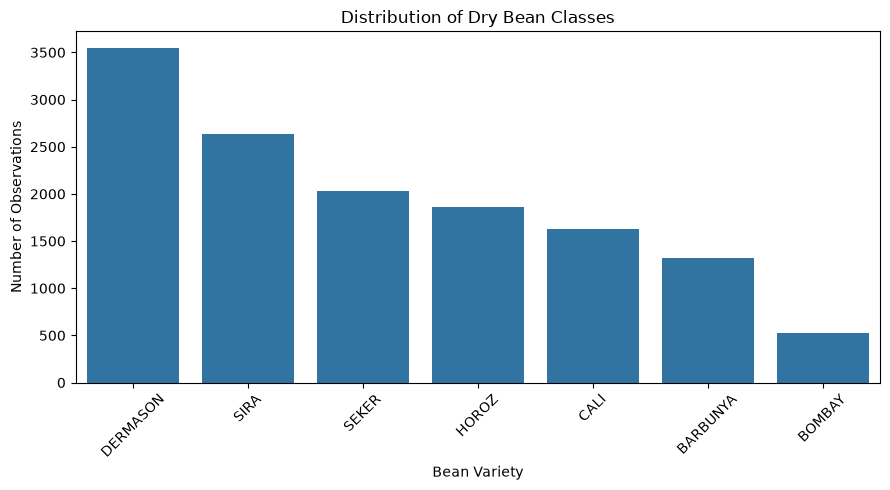

In [46]:
# count observations in each bean variety
class_counts = y.value_counts().sort_values(ascending=False)

print(class_counts)

# plot class distribution
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Class",
    order=class_counts.index
)

plt.title("Distribution of Dry Bean Classes")
plt.xlabel("Bean Variety")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

The class distribution shows how many observations belong to each bean variety. This is important because a heavily imbalanced dataset could cause a model to favor the most common classes. The class counts will also help determine whether accuracy alone is sufficient for evaluating the model.

Feature skewness:
Area               2.947136
ConvexArea         2.936102
ShapeFactor4      -2.760125
Solidity          -2.546877
MinorAxisLength    2.232013
EquivDiameter      1.947303
Perimeter          1.628018
MajorAxisLength    1.365813
Eccentricity      -1.064932
Extent            -0.895655
roundness         -0.648725
AspectRation       0.589045
ShapeFactor1      -0.530427
ShapeFactor2       0.294332
ShapeFactor3       0.242767
Compactness        0.036309
dtype: float64


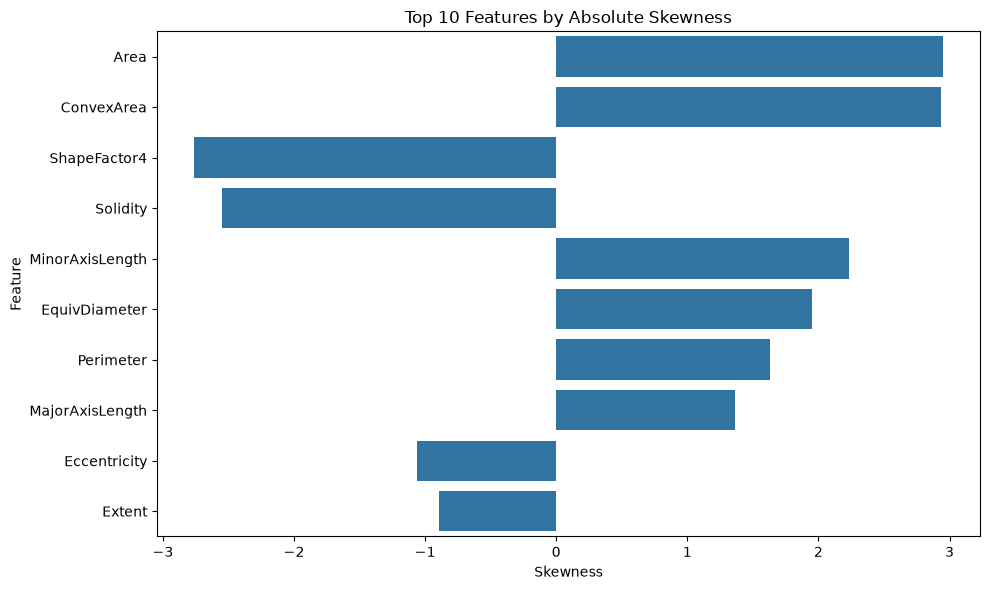

In [47]:
# calculate feature skewness
feature_skewness = X.skew().sort_values(
    key=abs,
    ascending=False
)

print("Feature skewness:")
print(feature_skewness)

# plot the features with the highest absolute skewness
plt.figure(figsize=(10, 6))

sns.barplot(
    x=feature_skewness.head(10).values,
    y=feature_skewness.head(10).index
)

plt.title("Top 10 Features by Absolute Skewness")
plt.xlabel("Skewness")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

Skewness can help identify any asymmetric distributions. If there are large positive/negative skewness values, there could be a concentration of values between certain points. We will use the StandardScaler to scale all the features. This will allow all the numeric features to be at the same scale, however does not remove skewness.

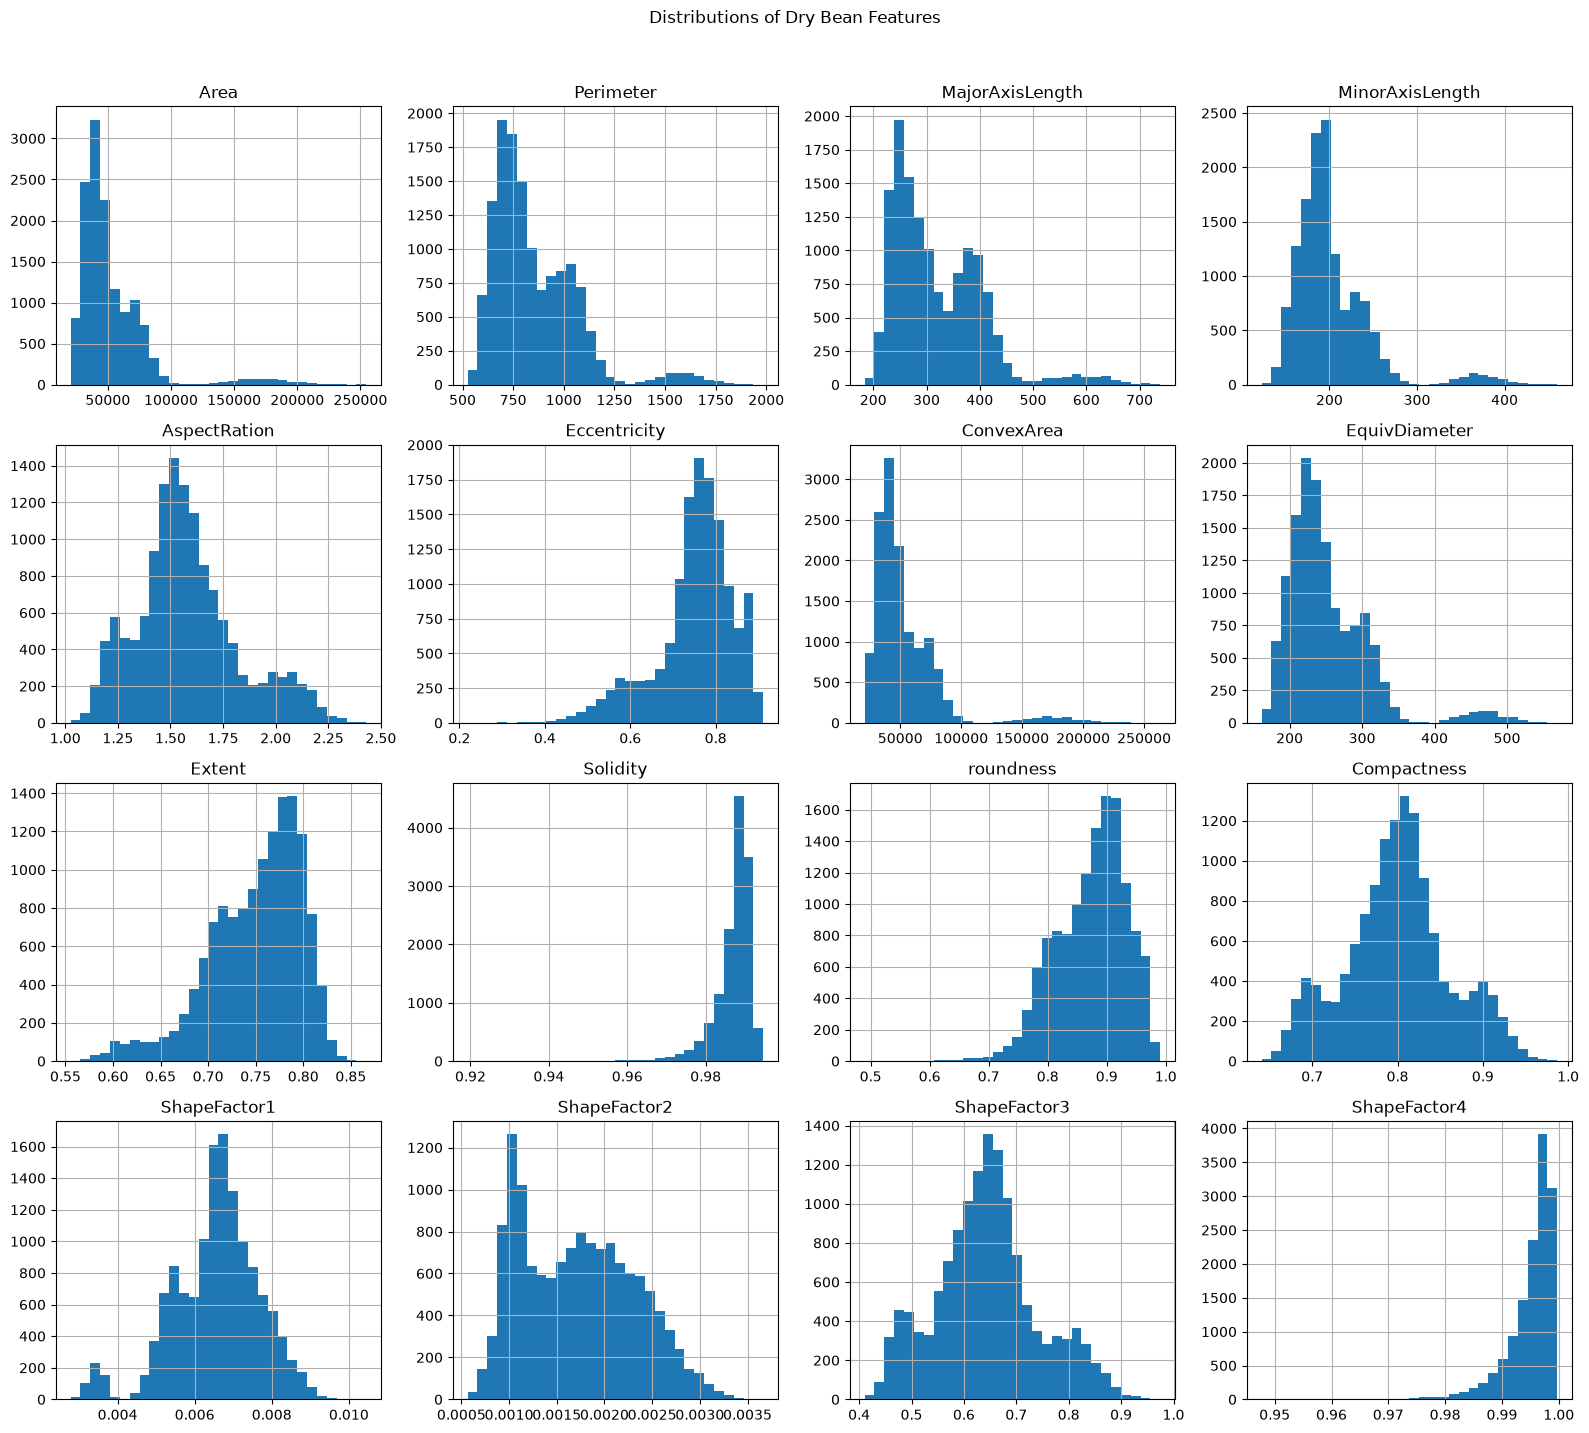

In [48]:
# display distributions for the numerical features
X.hist(
    figsize=(16, 14),
    bins=30
)

plt.suptitle("Distributions of Dry Bean Features", y=1.02)
plt.tight_layout()
plt.show()

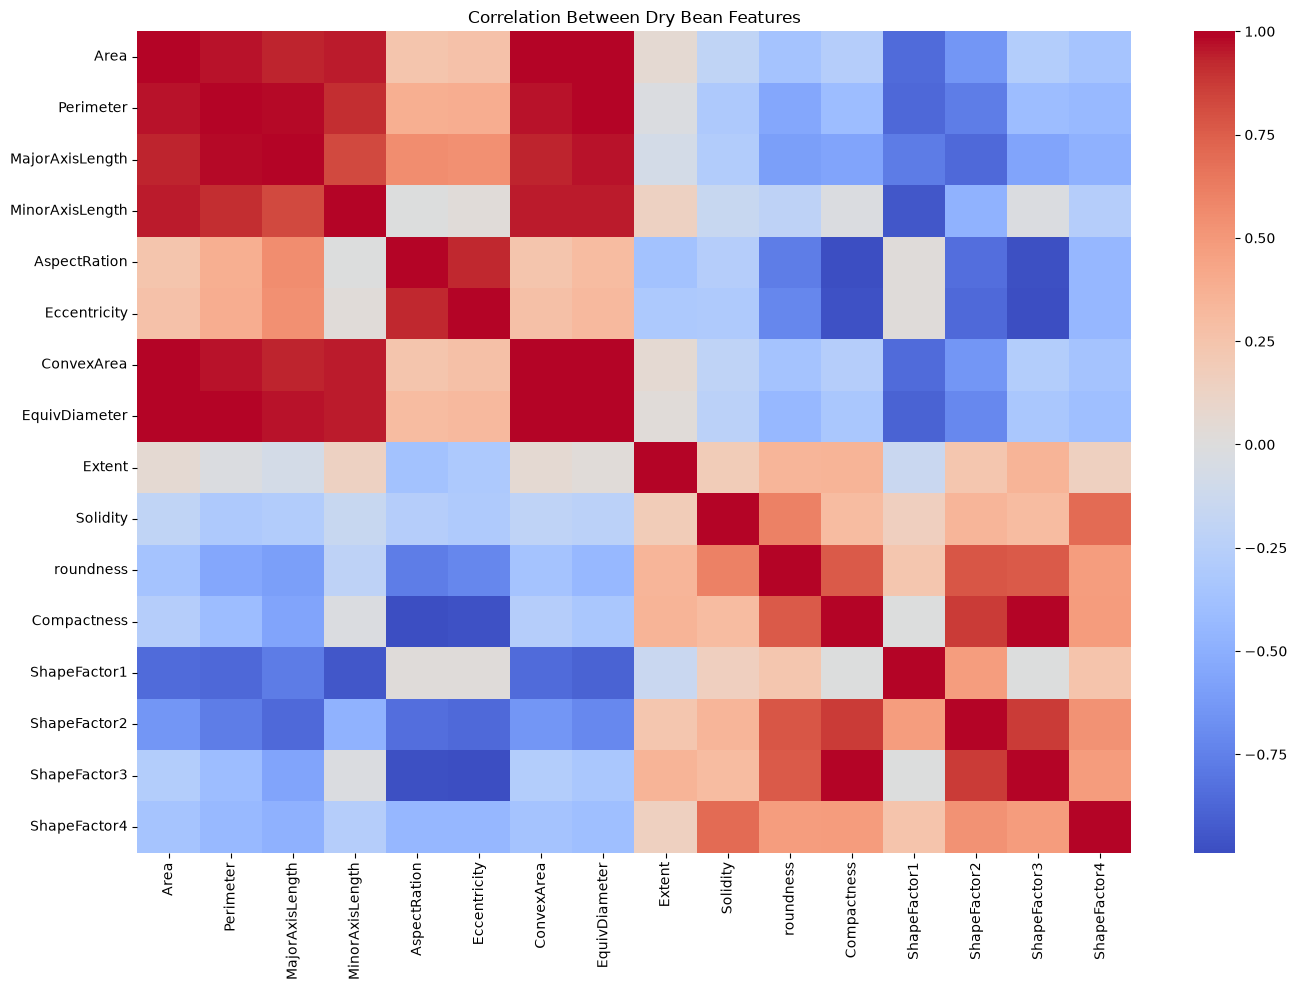

In [49]:
# calculate correlations between numerical features
correlation_matrix = X.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Between Dry Bean Features")
plt.tight_layout()
plt.show()

The correlations between variables are shown in this correlation heatmap. There are pairs of features that have high correlation as they measure similar geometric properties of the beans. This demonstrates there could be some redundant information within these measurements. Whilst the dense neural network can learn the relations between features, if the input features have high correlations it will be more difficult to understand what impact each feature has.

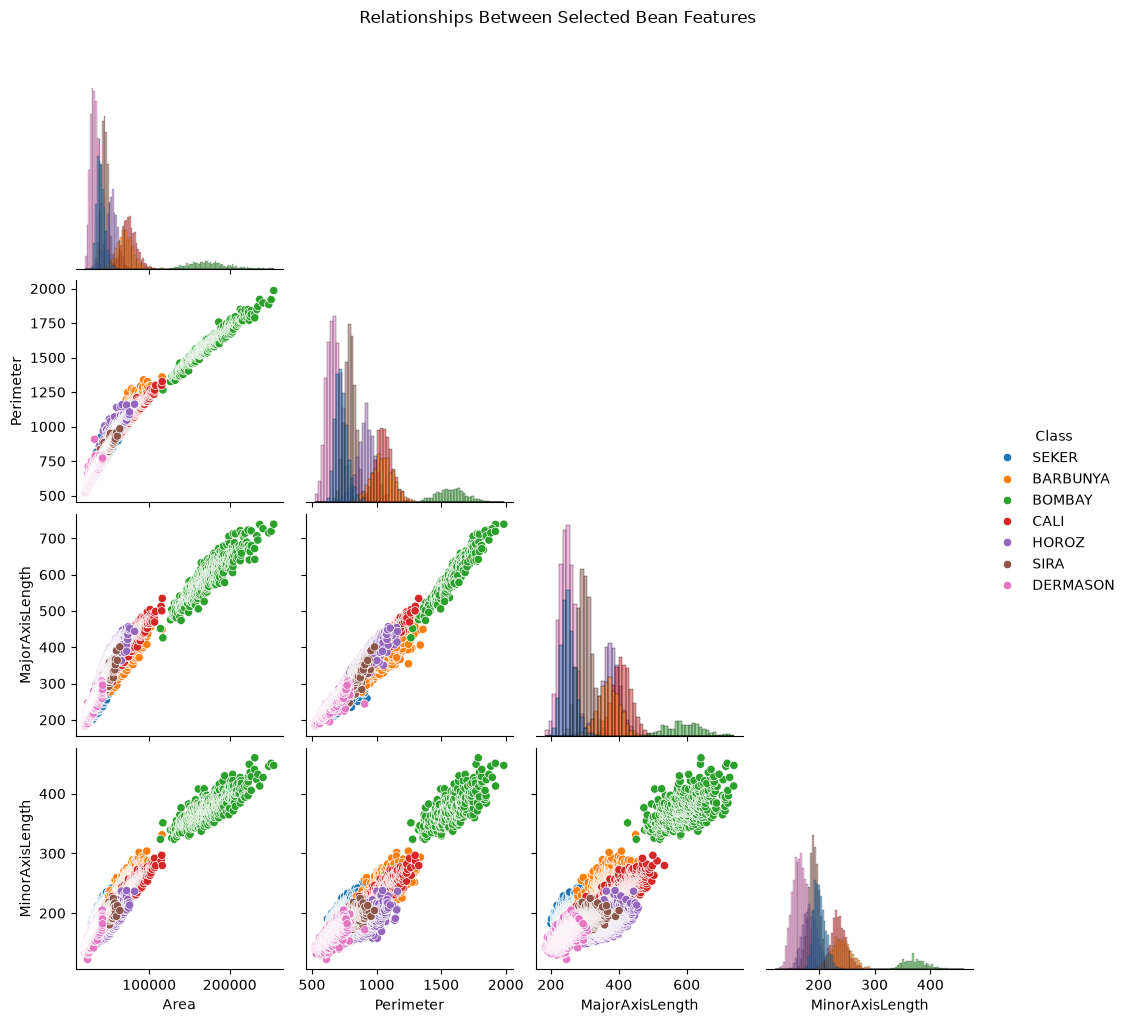

In [50]:
# select several features for a pairplot
relationship_features = [
    "Area",
    "Perimeter",
    "MajorAxisLength",
    "MinorAxisLength",
    "Class"
]

sns.pairplot(
    df[relationship_features],
    hue="Class",
    diag_kind="hist",
    corner=True
)

plt.suptitle("Relationships Between Selected Bean Features", y=1.02)
plt.show()

The pairplot shows several variables in relation to the beans’ shape and size. It helps us to see if the data can be separated into distinct categories of bean varieties. The overlap between the classes implies that some varieties may be hard to classify using only one feature. Using a neural network we can consider multiple measurements of data to classify into more complicated patterns.

## Preprocessing and Data Splitting

First, we encode the target using LabelEncoder to give them numeric values. We then split our data into training, validation and test sets using stratified sampling to maintain the class distribution across each set. Finally, we fit a StandardScaler on only the training set features and transform the validation and test sets to prevent any leakage from our evaluation data.

In [51]:
# encode the target labels
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

class_names = label_encoder.classes_

print("Encoded classes:")
for index, class_name in enumerate(class_names):
    print(index, "=", class_name)

# split off 15% for the final test set
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.15,
    random_state=RANDOM_STATE,
    stratify=y_encoded
)

# split the remaining data into training and validation sets
# This produces approximately 70% training, 15% validation, and 15% testing
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.17647,
    random_state=RANDOM_STATE,
    stratify=y_train_val
)

print("Training rows:", X_train.shape[0])
print("Validation rows:", X_val.shape[0])
print("Testing rows:", X_test.shape[0])

print("\nTraining features:", X_train.shape[1])
print("Validation features:", X_val.shape[1])
print("Testing features:", X_test.shape[1])

Encoded classes:
0 = BARBUNYA
1 = BOMBAY
2 = CALI
3 = DERMASON
4 = HOROZ
5 = SEKER
6 = SIRA
Training rows: 9479
Validation rows: 2032
Testing rows: 2032

Training features: 16
Validation features: 16
Testing features: 16


In [52]:
# display class counts for each split
print("Training class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nValidation class distribution:")
print(pd.Series(y_val).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training class distribution:
0     926
1     366
2    1140
3    2482
4    1302
5    1419
6    1844
Name: count, dtype: int64

Validation class distribution:
0    198
1     78
2    245
3    532
4    279
5    304
6    396
Name: count, dtype: int64

Testing class distribution:
0    198
1     78
2    245
3    532
4    279
5    304
6    396
Name: count, dtype: int64


In [53]:
# initialize the scaler
scaler = StandardScaler()

# fit the scaler using only the training data
X_train_scaled = scaler.fit_transform(X_train)

# apply the fitted scaler to validation and test data
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Validation data shape:", X_val_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

# check the scaled training feature means and standard deviations
print("\nTraining feature means:")
print(np.round(X_train_scaled.mean(axis=0), 3))

print("\nTraining feature standard deviations:")
print(np.round(X_train_scaled.std(axis=0), 3))

Training data shape: (9479, 16)
Validation data shape: (2032, 16)
Testing data shape: (2032, 16)

Training feature means:
[ 0. -0.  0.  0.  0. -0. -0. -0. -0. -0.  0. -0.  0.  0.  0.  0.]

Training feature standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


The StandardScaler was used since neural network models can often be very sensitive to scaling between features. This was fit just on the training set so we do not get any bias in our mean and standard deviation values when using the validation and test sets. All data was then transformed with the same scaling.

## Neural Network Model

The model used is a dense feed forward neural network. The model takes in 16 scaled numeric features. There are two hidden layers with ReLU activation functions. The model also includes dropout to combat overfitting. Finally there are 7 output neurons with softmax activation. Sparse categorical crossentropy was chosen as the loss function as the labels are integer encoded. Early stopping was used to monitor the validation loss and bring back the weights of the best epoch during training.

In [54]:
# number of input features and output classes
input_features = X_train_scaled.shape[1]
number_of_classes = len(class_names)

# build the neural network
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(input_features,)),

    tf.keras.layers.Dense(
        64,
        activation="relu"
    ),

    tf.keras.layers.Dropout(0.20),

    tf.keras.layers.Dense(
        32,
        activation="relu"
    ),

    tf.keras.layers.Dropout(0.20),

    tf.keras.layers.Dense(
        number_of_classes,
        activation="softmax"
    )
])

# compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# display model architecture
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,399 (13.28 KB)

 Trainable params: 3,399 (13.28 KB)

 Non-trainable params: 0 (0.00 B)

## Model Training

Once trained on the training set we can validate our model to see how it performs after each epoch. Using EarlyStopping means that we can stop our training once our loss during validation does not improve. This is useful because we can restore the best weights so that we won’t get a model from an epoch where our validation performance has worsened. We have a max of 100 epochs and 32 batch size. However, the actual number of epochs will be less if we hit early stopping.

In [55]:
# stop training when validation loss stops improving
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# reduce the learning rate when validation loss plateaus
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=0.00001
)

callbacks = [
    early_stopping,
    reduce_lr
]

In [56]:
# measure training time
start_time = time.time()

history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

training_time = time.time() - start_time

print("\nTraining completed.")
print("Training time:", round(training_time, 2), "seconds")
print("Epochs completed:", len(history.history["loss"]))

Epoch 1/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7353 - loss: 0.7602 - val_accuracy: 0.8824 - val_loss: 0.3297 - learning_rate: 0.0010
Epoch 2/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 913us/step - accuracy: 0.8812 - loss: 0.3463 - val_accuracy: 0.9158 - val_loss: 0.2444 - learning_rate: 0.0010
Epoch 3/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 869us/step - accuracy: 0.8981 - loss: 0.2989 - val_accuracy: 0.9213 - val_loss: 0.2285 - learning_rate: 0.0010
Epoch 4/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 885us/step - accuracy: 0.9097 - loss: 0.2689 - val_accuracy: 0.9154 - val_loss: 0.2216 - learning_rate: 0.0010
Epoch 5/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 876us/step - accuracy: 0.9105 - loss: 0.2646 - val_accuracy: 0.9203 - val_loss: 0.2144 - learning_rate: 0.0010
Epoch 6/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 869us/step - accuracy: 0.9126 - loss: 0.2526 - val_accuracy: 0.9183 - val_loss: 0.2136 - learning_rate: 0.0010
Epoch 7/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 863us/step - accuracy: 0.919

## Learning Curves

Training and validation accuracy and loss are plotted to examine how the model learns over time. These curves help identify possible overfitting, underfitting, or unstable training behavior.

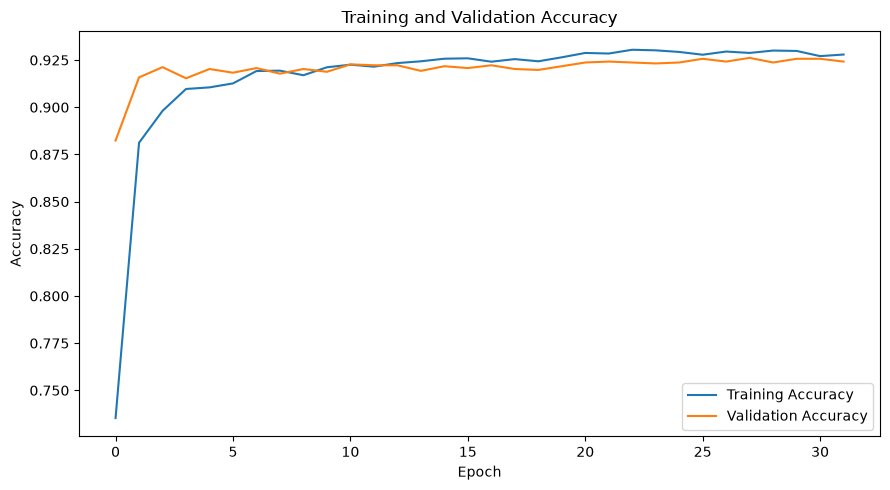

In [57]:
plt.figure(figsize=(9, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

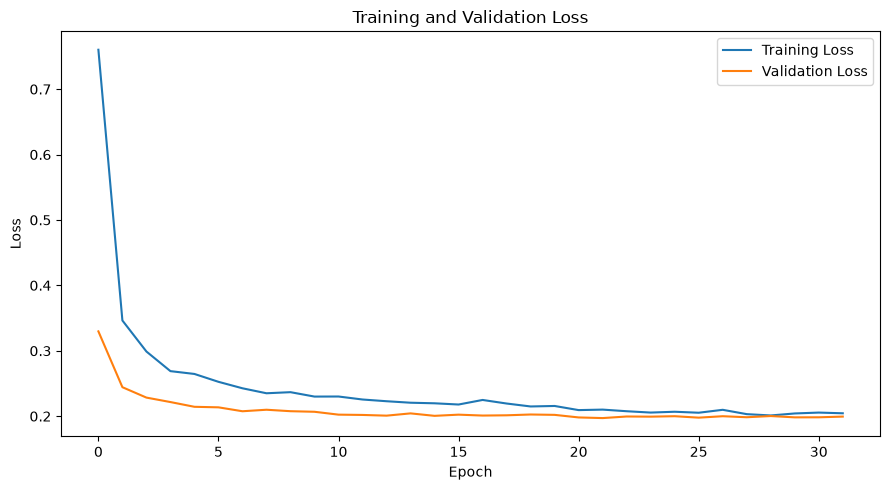

In [58]:
plt.figure(figsize=(9, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

These graphs show the performance of the training data and validation data through the epochs. If the training accuracy keeps increasing while the validation accuracy stagnates or decreases it may be an indication of overfitting within the model. This can be combated using early stopping which captures the weights for the epoch where the validation loss was lowest.

## Final Model Evaluation

The final model performance can be assessed on the held out test set. This was not used during training. The accuracy, macro F1 score and weighted F1 score are reported to give a fuller view of the performance on the multiclass task.

In [59]:
# get class probabilities for the test set
y_probabilities = model.predict(X_test_scaled)

# convert probabilities into predicted class labels
y_predictions = np.argmax(y_probabilities, axis=1)

# calculate evaluation metrics
test_accuracy = accuracy_score(
    y_test,
    y_predictions
)

macro_f1 = f1_score(
    y_test,
    y_predictions,
    average="macro"
)

weighted_f1 = f1_score(
    y_test,
    y_predictions,
    average="weighted"
)

print("Test Accuracy:", round(test_accuracy, 4))
print("Macro F1:", round(macro_f1, 4))
print("Weighted F1:", round(weighted_f1, 4))
print("Training Time:", round(training_time, 2), "seconds")

64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 720us/step
Test Accuracy: 0.9208
Macro F1: 0.933
Weighted F1: 0.9205
Training Time: 9.31 seconds


In [60]:
# display precision, recall, and F1 for each bean variety
report = classification_report(
    y_test,
    y_predictions,
    target_names=class_names,
    digits=4
)

print(report)

              precision    recall  f1-score   support

    BARBUNYA     0.9275    0.9040    0.9156       198
      BOMBAY     1.0000    1.0000    1.0000        78
        CALI     0.9176    0.9551    0.9360       245
    DERMASON     0.9011    0.9248    0.9128       532
       HOROZ     0.9673    0.9534    0.9603       279
       SEKER     0.9414    0.9507    0.9460       304
        SIRA     0.8810    0.8409    0.8605       396

    accuracy                         0.9208      2032
   macro avg     0.9337    0.9327    0.9330      2032
weighted avg     0.9206    0.9208    0.9205      2032



## Confusion Matrix

The confusion matrix allows us to compare the true and predicted variety of beans. The correct predictions can be seen down the diagonal of the matrix and any predictions that were incorrect can be seen away from the diagonal. This will allow us to see which varieties of beans are most commonly mixed up.

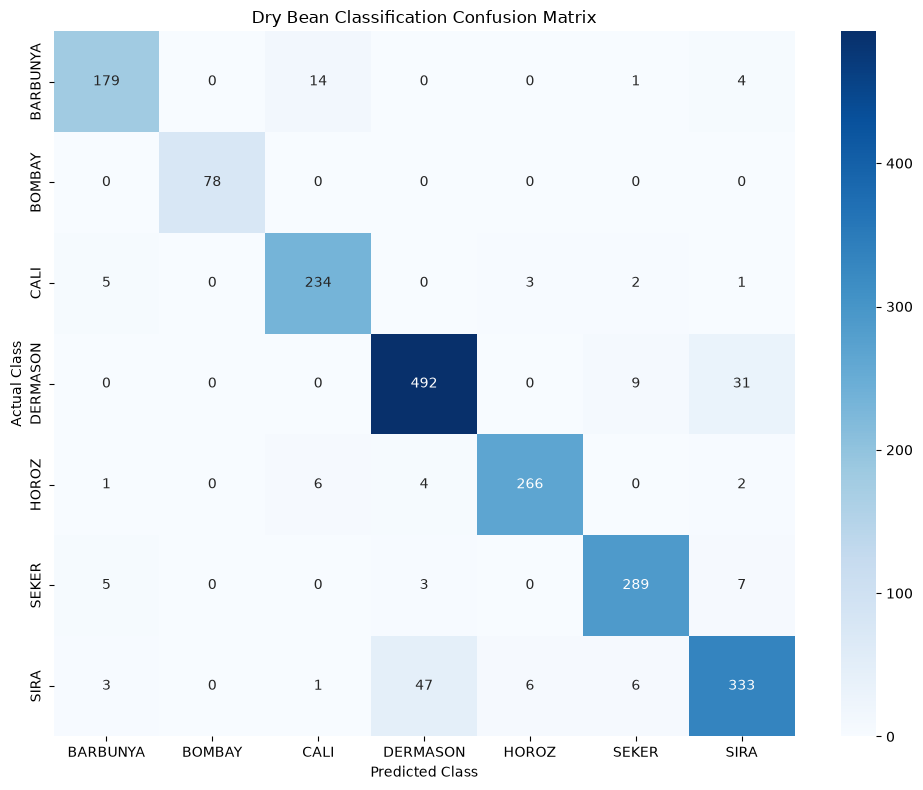

In [61]:
# calculate the confusion matrix
cm = confusion_matrix(
    y_test,
    y_predictions
)

# plot the confusion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Dry Bean Classification Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

## Class-wise Diagnostics

Overall accuracy does not tell you how accurate the model is for each bean variety. Instead we look at precision, recall and F1 score for each class to see if any varieties are more challenging to classify. Recall is particularly important for quality control applications, since it tells us how many of the real beans of a certain variety have been correctly identified.

In [62]:
# get a classification report as a dictionary
report_dict = classification_report(
    y_test,
    y_predictions,
    target_names=class_names,
    output_dict=True
)

# convert the report into a DataFrame
class_results = pd.DataFrame(report_dict).T

# display the individual class metrics
display(
    class_results.loc[
        class_names,
        ["precision", "recall", "f1-score", "support"]
    ]
)

,precision,recall,f1-score,support
BARBUNYA,0.927461,0.904040,0.915601,198.0
BOMBAY,1.000000,1.000000,1.000000,78.0
CALI,0.917647,0.955102,0.936000,245.0
DERMASON,0.901099,0.924812,0.912801,532.0
HOROZ,0.967273,0.953405,0.960289,279.0
SEKER,0.941368,0.950658,0.945990,304.0
SIRA,0.880952,0.840909,0.860465,396.0


In [63]:
# find the class with the highest and lowest F1 scores
class_f1 = class_results.loc[class_names, "f1-score"]

best_class = class_f1.idxmax()
worst_class = class_f1.idxmin()

print("Highest-performing class:", best_class)
print("F1 score:", round(class_f1.max(), 4))

print("\nLowest-performing class:", worst_class)
print("F1 score:", round(class_f1.min(), 4))

Highest-performing class: BOMBAY
F1 score: 1.0

Lowest-performing class: SIRA
F1 score: 0.8605


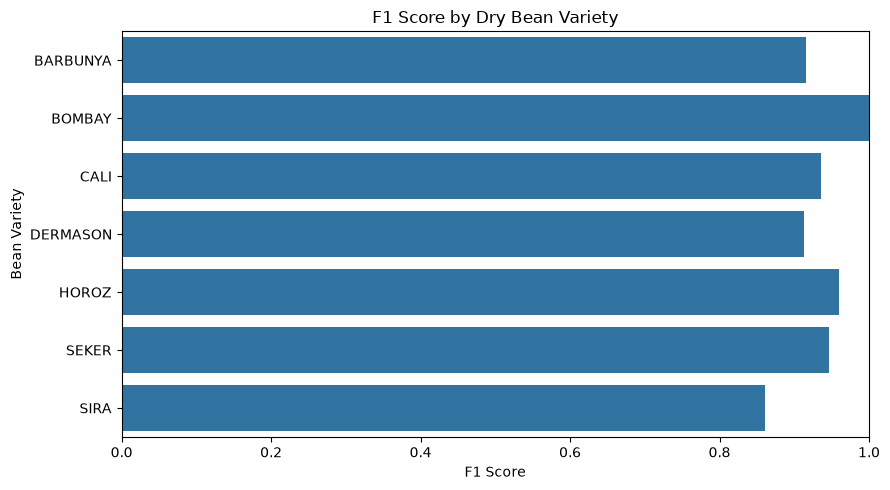

In [64]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=class_f1.values,
    y=class_f1.index
)

plt.title("F1 Score by Dry Bean Variety")
plt.xlabel("F1 Score")
plt.ylabel("Bean Variety")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()

The class-wise results allow us to see which bean varieties are harder to classify. Classes with lower recall will have more true beans being misclassified. The reasons for these errors should be looked into as it may affect agricultural quality control decisions. The confusion matrix is useful as it shows which classes are being confused. The classification report summarises the precision, recall and F1 score of each variety.

## Prediction Confidence

The model will give a probability for each of the seven different types of bean. The highest probability is taken as the predicted class. However, predictions that are relatively uncertain may require further investigation. A threshold for the confidence can be set as an example of how a quality control check could be performed. This is not a verified requirement for production and would need to be decided based on operational risk and validation data.

In [65]:
# get the highest predicted probability for each test observation
prediction_confidence = np.max(
    y_probabilities,
    axis=1
)

# example review threshold
confidence_threshold = 0.70

# identify predictions below the threshold
low_confidence = prediction_confidence < confidence_threshold

print("Total test predictions:", len(y_predictions))
print("Low-confidence predictions:", low_confidence.sum())

print(
    "Percentage requiring review:",
    round(low_confidence.mean() * 100, 2),
    "%"
)

# display several low-confidence predictions
low_confidence_results = pd.DataFrame({
    "Actual": label_encoder.inverse_transform(y_test[low_confidence]),
    "Predicted": label_encoder.inverse_transform(y_predictions[low_confidence]),
    "Confidence": prediction_confidence[low_confidence]
})

display(low_confidence_results.head(10))

Total test predictions: 2032
Low-confidence predictions: 167
Percentage requiring review: 8.22 %


,Actual,Predicted,Confidence
0,SIRA,DERMASON,0.667192
1,SIRA,SIRA,0.616639
2,SIRA,SIRA,0.514276
3,SIRA,SIRA,0.689260
4,SIRA,DERMASON,0.532857
5,HOROZ,HOROZ,0.591730
6,SIRA,SIRA,0.600957
7,SEKER,DERMASON,0.607711
8,CALI,CALI,0.611612
9,SIRA,SIRA,0.596475


## Model and Preprocessing Artifacts

The trained model, scaler, and label encoder are saved as separate artifacts. Keeping the preprocessing objects with the model is important because future predictions must use the same feature scaling and class encoding used during training.

In [66]:
# create a folder for saved artifacts
artifact_folder = "dry_bean_model_artifacts"

os.makedirs(artifact_folder, exist_ok=True)

# save the trained Keras model
model.save(
    os.path.join(artifact_folder, "dry_bean_classifier.keras")
)

# save the scaler
joblib.dump(
    scaler,
    os.path.join(artifact_folder, "standard_scaler.joblib")
)

# save the label encoder
joblib.dump(
    label_encoder,
    os.path.join(artifact_folder, "label_encoder.joblib")
)

# save feature names and experiment settings
metadata = {
    "random_state": RANDOM_STATE,
    "features": X.columns.tolist(),
    "classes": class_names.tolist(),
    "confidence_review_threshold": confidence_threshold,
    "training_time_seconds": round(training_time, 2),
    "test_accuracy": float(test_accuracy),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1)
}

with open(
    os.path.join(artifact_folder, "metadata.json"),
    "w"
) as file:
    json.dump(metadata, file, indent=4)

print("Model and preprocessing artifacts saved.")

Model and preprocessing artifacts saved.


In [67]:
# load the saved model and preprocessing objects
loaded_model = tf.keras.models.load_model(
    os.path.join(artifact_folder, "dry_bean_classifier.keras")
)

loaded_scaler = joblib.load(
    os.path.join(artifact_folder, "standard_scaler.joblib")
)

loaded_encoder = joblib.load(
    os.path.join(artifact_folder, "label_encoder.joblib")
)

# get predictions using the loaded model
sample_predictions = loaded_model.predict(
    loaded_scaler.transform(X_test.iloc[:5])
)

sample_classes = np.argmax(
    sample_predictions,
    axis=1
)

print("Sample predictions:")
print(loaded_encoder.inverse_transform(sample_classes))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
Sample predictions:
['DERMASON' 'DERMASON' 'SEKER' 'SIRA' 'CALI']


### Reproducibility

The experiment was conducted using a fixed random seed for Python, NumPy and TensorFlow. The same training/validation/test split was used and the scaling and label encoding of the data was saved to be used on the trained model when making future predictions. The model architecture, feature names and performance metrics were also saved within a metadata file. The reproducibility may vary depending on the hardware, version of TensorFlow and environment it is run in.

### Experiment Logging

It is important to keep track of details such as the data version, feature names, random seed, train/validation split sizes, model architecture, optimizer, learning rate, batch size, number of epochs, and final evaluation metrics. Keeping track of the model training time and model artefacts will help you understand and compare results from future experiments and identify any unexpected changes in performance.

### Monitoring

The deployed classification model should be monitored for accuracy, latency, failed data transformations, missing data, unexpected numerical data, and confidence of predictions. Once real labels become available for the beans, the system should monitor accuracy, precision, recall, and F1 scores. Predictions with low confidence should be flagged as well as any unexpected inputs.

### Data and Concept Drift

There are various reasons why feature drift may occur, including changes to imaging hardware, lighting, measurement methods or beans. Summary statistics or drift measures (Population Stability Index) should be used to compare distributions of features to the training baseline. We should also monitor changes to predicted class distribution. Once true labels are available we can monitor changes to recall and F1 across classes to detect concept drift.

### Compute Cost

The network is simple so it will train fine on a regular CPU without requiring a large GPU. The batch processing means that the model can be used to classify large amounts of beans with little inference overhead. Consider the complexity of the model and training time required versus the increase in performance.

### Deployment Risk and Rollback

Misclassification may have implications for sorting and quality control processes in agriculture. As a result, it is important to initially test this model under either a testing or manual review process. Input validation, confidence based review, and performance monitoring per class should be applied when deploying the model. If the model performs below an agreed threshold, the model should revert back to the previously validated model. This means keeping a record of the scaler, label encoder, model and metadata, so that we can easily revert to the previous version.

### Future Experiments

We can try experimenting by changing different hyperparameters such as the number of hidden layer nodes, the dropout rate, learning rate and batch size. We can also improve our model by comparing it with Random Forest and Gradient Boosted Tree models. We can also experiment with more regularisation methods. When making any new models we must ensure they are evaluated using the same method and the test data is kept untouched until evaluation.

## Evaluation Summary

The UCI Dry Bean dataset was used to classify the seven different varieties of beans using 16 numerical features. Data validation was conducted to ensure there were no missing values, duplicate values, correct feature types, valid class labels and numerical values. The data was then split into training, validation and testing sets using stratified sampling. Only the training data was fit to the StandardScaler to prevent any data leakage. A two layer hidden neural network was used with ReLU activation, dropout regularisation and a 7 neuron output softmax layer. Early stopping was applied to keep track of the validation loss, and return the best weights. The final model was assessed using the test accuracy, macro F1, weighted F1 score, classification report and confusion matrix. This gives an overall view of how the model is performing whilst also showing how it is performing per bean variety. The results can be viewed per class so we can see which varieties are proving to be harder to classify and may require further quality control checks. The model provides a base for an agricultural classification system. Further testing should be carried out before deploying the model in production to understand how it will perform on new image measurements. We should also check for drift in the feature distributions and determine an acceptable error rate for each variety of beans.

## Conclusion

This assignment demonstrates a full example of a Keras classification problem using the UCI Dry Bean dataset. Data validation and exploration was completed before any pre-processing was applied. Training, validation and test datasets were created to avoid any information leakage. The StandardScaler was then fit to only the training data. The dense neural network was trained including dropout and early stopping to help reduce overfitting. The neural network was then evaluated using various classification metrics. The confusion matrix and F1 scores per class give further understanding of what types of classification errors are occurring. From a systems viewpoint, it is important to make sure the model can be reproduced, have logging, monitoring, drift detection and rollback plans in place. Future work could include comparing the neural network to tree based models, experimenting with different neural network architectures and evaluating the performance with new measurements of beans.